# 02 — Error Analysis & OOV Stress-Testing

Mục tiêu của notebook này:
1. **OOV Stress-Testing:** So sánh khả năng nhận diện kỹ năng quen thuộc (**In-vocab**) vs kỹ năng mới toanh (**Out-of-Vocabulary** — 31.8% từ EDA).
2. **Phân loại 3 nhóm lỗi kinh điển:**
   - **False Negatives (FN):** Bỏ sót kỹ năng thật (do OOV hay do ngữ cảnh?).
   - **False Positives (FP):** Báo động giả (đoán nhầm danh từ chung, vị trí, công cụ thành skill).
   - **Boundary Mismatch:** Bắt trúng từ khóa nhưng sai ranh giới (ví dụ bắt `Spring` thay vì `Spring Boot`).
3. **Case Studies trực quan:** Xem trực tiếp từng câu văn thực tế trong tập Test để hiểu nguyên nhân mô hình sai.

## 1. Khởi tạo thư viện & cấu hình đường dẫn

In [1]:
import json
from pathlib import Path
import torch
import pandas as pd
import matplotlib.pyplot as plt
from transformers import AutoTokenizer, AutoModelForTokenClassification

# Tự động phát hiện thư mục gốc (dù đang chạy từ repo root hay từ bên trong notebooks/)
if Path("data/splits").exists():
    ROOT = Path(".")
elif Path("../data/splits").exists():
    ROOT = Path("..")
else:
    raise FileNotFoundError("Không tìm thấy thư mục data/splits")

MODEL_DIR = ROOT / "model" / "best"
TRAIN_PATH = ROOT / "data" / "splits" / "train.json"
TEST_PATH = ROOT / "data" / "splits" / "test.json"

print(f"Thư mục gốc: {ROOT.resolve()}")
print(f"Model checkpoint: {MODEL_DIR}")

c:\Users\Pham Thai\miniconda3\envs\ner_venv\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Thư mục gốc: E:\vietnamese-job-skill-ner
Model checkpoint: ..\model\best


## 2. Nạp dữ liệu & Xây dựng tập từ vựng kỹ năng (Train Vocab)

In [2]:
def extract_spans_from_bio(tokens, labels):
    """Trích xuất danh sách các span kỹ năng từ cặp (tokens, labels) theo chuẩn BIO."""
    spans = []
    current = []
    for token, label in zip(tokens, labels):
        if label == "B-SKILL":
            if current:
                spans.append(" ".join(current))
            current = [token]
        elif label == "I-SKILL":
            if current:
                current.append(token)
            else:
                current = [token]
        else:  # 'O'
            if current:
                spans.append(" ".join(current))
                current = []
    if current:
        spans.append(" ".join(current))
    return spans

# 1. Nạp Train set để lấy toàn bộ từ vựng kỹ năng đã học (In-vocab)
with open(TRAIN_PATH, encoding="utf-8") as f:
    train_data = json.load(f)

train_vocab = set()
for s in train_data:
    for span in extract_spans_from_bio(s["tokens"], s["labels"]):
        train_vocab.add(span.lower())

# 2. Nạp Test set
with open(TEST_PATH, encoding="utf-8") as f:
    test_data = json.load(f)

print(f"- Số mẫu Train: {len(train_data)} câu")
print(f"- Tổng số kỹ năng unique trong Train: {len(train_vocab)} kỹ năng")
print(f"- Số mẫu Test: {len(test_data)} câu")

- Số mẫu Train: 244 câu
- Tổng số kỹ năng unique trong Train: 145 kỹ năng
- Số mẫu Test: 54 câu


## 3. Tải mô hình PhoBERT-base (`model/best`)

In [3]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Đang tải mô hình lên: {device}...")

tokenizer = AutoTokenizer.from_pretrained(str(MODEL_DIR), use_fast=True)
model = AutoModelForTokenClassification.from_pretrained(str(MODEL_DIR))
model.to(device)
model.eval()

id2label = model.config.id2label
cls_id = tokenizer.bos_token_id or tokenizer.cls_token_id
sep_id = tokenizer.eos_token_id or tokenizer.sep_token_id
print("Tải mô hình thành công! Nhãn nhị phân / phân loại:", id2label)

Đang tải mô hình lên: cpu...


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 6263.44it/s]

Tải mô hình thành công! Nhãn nhị phân / phân loại: {0: 'O', 1: 'B-SKILL', 2: 'I-SKILL'}


## 4. Chạy suy luận (Inference) & Phân tích lỗi trên 54 câu Test

In [4]:
total_gold_entities = 0
total_pred_entities = 0

iv_total = 0
iv_exact_tp = 0
iv_soft_tp = 0

oov_total = 0
oov_exact_tp = 0
oov_soft_tp = 0

fn_records = []       # False Negatives (bỏ sót)
fp_records = []       # False Positives (đoán nhầm)
boundary_records = [] # Boundary Mismatches (sai ranh giới)
case_studies = []     # Toàn bộ câu có lỗi để phân tích ngữ cảnh

for idx, sample in enumerate(test_data):
    tokens = sample["tokens"]
    gold_labels = sample["labels"]
    gold_spans = extract_spans_from_bio(tokens, gold_labels)
    total_gold_entities += len(gold_spans)
    
    for g_span in gold_spans:
        if g_span.lower() in train_vocab:
            iv_total += 1
        else:
            oov_total += 1

    # Tokenize word-by-word
    input_ids = [cls_id]
    word_ids = [None]
    for w_idx, word in enumerate(tokens):
        subwords = tokenizer.encode(word, add_special_tokens=False)
        if not subwords:
            continue
        input_ids.extend(subwords)
        word_ids.extend([w_idx] * len(subwords))
    input_ids.append(sep_id)
    word_ids.append(None)

    # Model Forward Pass
    inp_tensor = torch.tensor([input_ids], device=device)
    with torch.no_grad():
        outputs = model(inp_tensor)
        preds = torch.argmax(outputs.logits, dim=-1)[0].cpu().tolist()

    # Decode subword đầu tiên cho mỗi word
    word_preds = {}
    seen_words = set()
    for wid, pid in zip(word_ids, preds):
        if wid is not None and wid not in seen_words:
            word_preds[wid] = id2label.get(pid, "O")
            seen_words.add(wid)

    pred_labels = [word_preds.get(w_idx, "O") for w_idx in range(len(tokens))]
    pred_spans = extract_spans_from_bio(tokens, pred_labels)
    total_pred_entities += len(pred_spans)

    # Đối chiếu Spans
    gold_matched = set()
    pred_matched = set()

    # 1. Exact Match
    for g_idx, g_span in enumerate(gold_spans):
        for p_idx, p_span in enumerate(pred_spans):
            if p_idx not in pred_matched and g_span.lower() == p_span.lower():
                gold_matched.add(g_idx)
                pred_matched.add(p_idx)
                is_oov = g_span.lower() not in train_vocab
                if is_oov:
                    oov_exact_tp += 1
                    oov_soft_tp += 1
                else:
                    iv_exact_tp += 1
                    iv_soft_tp += 1
                break

    # 2. Boundary Mismatch (chồng lấn chuỗi)
    for g_idx, g_span in enumerate(gold_spans):
        if g_idx in gold_matched:
            continue
        for p_idx, p_span in enumerate(pred_spans):
            if p_idx in pred_matched:
                continue
            g_low, p_low = g_span.lower(), p_span.lower()
            if g_low in p_low or p_low in g_low:
                gold_matched.add(g_idx)
                pred_matched.add(p_idx)
                is_oov = g_span.lower() not in train_vocab
                if is_oov:
                    oov_soft_tp += 1
                else:
                    iv_soft_tp += 1
                boundary_records.append({
                    "Sentence_ID": idx + 1,
                    "Gold_Span": g_span,
                    "Pred_Span": p_span,
                    "Is_OOV": is_oov
                })
                break

    # 3. False Negatives (Bỏ sót)
    for g_idx, g_span in enumerate(gold_spans):
        if g_idx not in gold_matched:
            is_oov = g_span.lower() not in train_vocab
            fn_records.append({
                "Sentence_ID": idx + 1,
                "Skill": g_span,
                "Is_OOV": is_oov,
                "Sentence": " ".join(tokens)
            })

    # 4. False Positives (Đoán thừa)
    for p_idx, p_span in enumerate(pred_spans):
        if p_idx not in pred_matched:
            fp_records.append({
                "Sentence_ID": idx + 1,
                "Predicted_Skill": p_span,
                "Sentence": " ".join(tokens)
            })

    # Lưu case study nếu có bất kỳ lỗi nào
    if len(gold_matched) < len(gold_spans) or len(pred_matched) < len(pred_spans):
        case_studies.append({
            "Sentence_ID": idx + 1,
            "Sentence": " ".join(tokens),
            "Gold_Skills": gold_spans,
            "Pred_Skills": pred_spans
        })

print(f">>> Hoàn tất đánh giá trên 54 câu tập Test!")
print(f"- Tổng Gold: {total_gold_entities} entities | Tổng Pred: {total_pred_entities} entities")

>>> Hoàn tất đánh giá trên 54 câu tập Test!
- Tổng Gold: 74 entities | Tổng Pred: 81 entities


## 5. Bảng OOV Stress-Testing: In-vocab vs OOV Entity Recall

So sánh khả năng nhận diện kỹ năng **In-vocabulary (đã học)** vs **OOV (chưa từng thấy ở tập Train)**:

In [5]:
df_oov_summary = pd.DataFrame([
    {
        "Nhóm kỹ năng": "In-vocabulary (Đã thấy ở Train)",
        "Số entity (Test)": f"{iv_total} ({iv_total/total_gold_entities:.1%})",
        "Exact Match Recall": f"{iv_exact_tp/iv_total:.1%} ({iv_exact_tp}/{iv_total})",
        "Soft Match Recall (gồm Boundary)": f"{iv_soft_tp/iv_total:.1%} ({iv_soft_tp}/{iv_total})",
        "Độ lệch Recall (vs In-vocab)": "Baseline"
    },
    {
        "Nhóm kỹ năng": "Out-of-Vocabulary (Mới toanh)",
        "Số entity (Test)": f"{oov_total} ({oov_total/total_gold_entities:.1%})",
        "Exact Match Recall": f"{oov_exact_tp/oov_total:.1%} ({oov_exact_tp}/{oov_total})",
        "Soft Match Recall (gồm Boundary)": f"{oov_soft_tp/oov_total:.1%} ({oov_soft_tp}/{oov_total})",
        "Độ lệch Recall (vs In-vocab)": f"{oov_exact_tp/oov_total - iv_exact_tp/iv_total:+.1%} (Exact) / {oov_soft_tp/oov_total - iv_soft_tp/iv_total:+.1%} (Soft)"
    },
    {
        "Nhóm kỹ năng": "TOÀN BỘ TẬP TEST",
        "Số entity (Test)": f"{total_gold_entities} (100.0%)",
        "Exact Match Recall": f"{(iv_exact_tp + oov_exact_tp)/total_gold_entities:.1%} ({iv_exact_tp + oov_exact_tp}/{total_gold_entities})",
        "Soft Match Recall (gồm Boundary)": f"{(iv_soft_tp + oov_soft_tp)/total_gold_entities:.1%} ({iv_soft_tp + oov_soft_tp}/{total_gold_entities})",
        "Độ lệch Recall (vs In-vocab)": "—"
    }
])

# Hiển thị bảng tổng hợp
df_oov_summary

,Nhóm kỹ năng,Số entity (Test),Exact Match Recall,Soft Match Recall (gồm Boundary),Độ lệch Recall (vs In-vocab)
0,In-vocabulary (Đã thấy ở Train),52 (70.3%),71.2% (37/52),90.4% (47/52),Baseline
1,Out-of-Vocabulary (Mới toanh),22 (29.7%),54.5% (12/22),77.3% (17/22),-16.6% (Exact) / -13.1% (Soft)
2,TOÀN BỘ TẬP TEST,74 (100.0%),66.2% (49/74),86.5% (64/74),—


### Biểu đồ trực quan hóa OOV Stress-testing

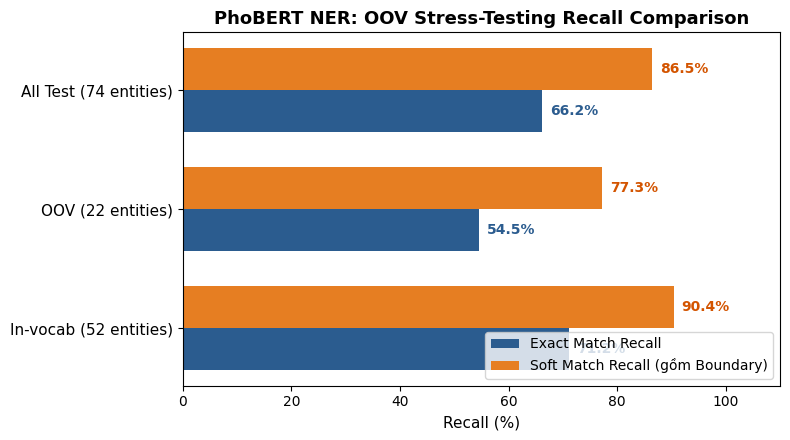

In [6]:
categories = ["In-vocab (52 entities)", "OOV (22 entities)", "All Test (74 entities)"]
exact_recalls = [iv_exact_tp/iv_total * 100, oov_exact_tp/oov_total * 100, (iv_exact_tp + oov_exact_tp)/total_gold_entities * 100]
soft_recalls = [iv_soft_tp/iv_total * 100, oov_soft_tp/oov_total * 100, (iv_soft_tp + oov_soft_tp)/total_gold_entities * 100]

fig, ax = plt.subplots(figsize=(8, 4.5))
y_positions = [0, 1, 2]
bar_width = 0.35

bars1 = ax.barh([y - bar_width/2 for y in y_positions], exact_recalls, height=bar_width, label="Exact Match Recall", color="#2b5c8f")
bars2 = ax.barh([y + bar_width/2 for y in y_positions], soft_recalls, height=bar_width, label="Soft Match Recall (gồm Boundary)", color="#e67e22")

ax.set_yticks(y_positions)
ax.set_yticklabels(categories, fontsize=11)
ax.set_xlabel("Recall (%)", fontsize=11)
ax.set_title("PhoBERT NER: OOV Stress-Testing Recall Comparison", fontsize=13, fontweight="bold")
ax.set_xlim(0, 110)
ax.legend(loc="lower right")

# Hiển thị giá trị phần trăm trên từng cột
for bar in bars1:
    w = bar.get_width()
    ax.text(w + 1.5, bar.get_y() + bar.get_height()/2, f"{w:.1f}%", va="center", fontsize=10, fontweight="bold", color="#2b5c8f")
for bar in bars2:
    w = bar.get_width()
    ax.text(w + 1.5, bar.get_y() + bar.get_height()/2, f"{w:.1f}%", va="center", fontsize=10, fontweight="bold", color="#d35400")

plt.tight_layout()
plt.show()

## 6. Phân loại 3 nhóm lỗi tổng thể

In [7]:
total_errors = len(fn_records) + len(fp_records) + len(boundary_records)
oov_fn_count = sum(1 for r in fn_records if r["Is_OOV"])

df_error_dist = pd.DataFrame([
    {
        "Loại lỗi": "False Negatives (Bỏ sót)",
        "Số lượng": len(fn_records),
        "Tỉ lệ / Tổng lỗi": f"{len(fn_records)/total_errors:.1%}",
        "Bản chất nguyên nhân": f"Bỏ sót kỹ năng thật ({oov_fn_count}/{len(fn_records)} ca do OOV từ mới)"
    },
    {
        "Loại lỗi": "False Positives (Báo động giả)",
        "Số lượng": len(fp_records),
        "Tỉ lệ / Tổng lỗi": f"{len(fp_records)/total_errors:.1%}",
        "Bản chất nguyên nhân": "Đoán nhầm thuật ngữ công việc hoặc danh từ chung thành skill"
    },
    {
        "Loại lỗi": "Boundary Mismatch (Sai ranh giới)",
        "Số lượng": len(boundary_records),
        "Tỉ lệ / Tổng lỗi": f"{len(boundary_records)/total_errors:.1%}",
        "Bản chất nguyên nhân": "Bắt trúng từ khóa chính nhưng cắt thiếu/thừa từ phụ (compound skill)"
    },
    {
        "Loại lỗi": "TỔNG CỘNG LỖI",
        "Số lượng": total_errors,
        "Tỉ lệ / Tổng lỗi": "100.0%",
        "Bản chất nguyên nhân": f"Đánh giá trên 74 entity nhãn chuẩn"
    }
])

df_error_dist

,Loại lỗi,Số lượng,Tỉ lệ / Tổng lỗi,Bản chất nguyên nhân
0,False Negatives (Bỏ sót),10,23.8%,Bỏ sót kỹ năng thật (5/10 ca do OOV từ mới)
1,False Positives (Báo động giả),17,40.5%,Đoán nhầm thuật ngữ công việc hoặc danh từ chu...
2,Boundary Mismatch (Sai ranh giới),15,35.7%,Bắt trúng từ khóa chính nhưng cắt thiếu/thừa t...
3,TỔNG CỘNG LỖI,42,100.0%,Đánh giá trên 74 entity nhãn chuẩn


## 7. Chi tiết từng dạng lỗi

### A. Danh sách False Negatives (Bỏ sót kỹ năng)

In [8]:
df_fn = pd.DataFrame(fn_records)
print(f"Tổng số False Negatives: {len(df_fn)} ca (trong đó {oov_fn_count} ca là OOV)")
df_fn[["Sentence_ID", "Skill", "Is_OOV", "Sentence"]]

Tổng số False Negatives: 10 ca (trong đó 5 ca là OOV)


,Sentence_ID,Skill,Is_OOV,Sentence
0,8,Linux,False,Implemented system metric parsers (/ proc / st...
1,21,React Native,False,"Tối thiểu 1 , 5 năm React Native ."
2,35,Microservice Architecture,True,Có kinh nghiệm thiết kế hệ thống Microservice ...
3,40,PostgreSQL,False,Thiết kế và xử lý dữ liệu với PostgreSQL / SQL...
4,40,JPA,True,Thiết kế và xử lý dữ liệu với PostgreSQL / SQL...
5,41,Vector Database,False,"Có kinh nghiệm với : LLM Agents ( GPT , Gemini..."
6,41,Agents,False,"Có kinh nghiệm với : LLM Agents ( GPT , Gemini..."
7,41,Function Calling,True,"Có kinh nghiệm với : LLM Agents ( GPT , Gemini..."
8,52,Function Calling,True,Nghiên cứu và ứng dụng các kỹ thuật mới : RAG ...
9,52,Reinforcement Learning Agents,True,Nghiên cứu và ứng dụng các kỹ thuật mới : RAG ...


### B. Danh sách False Positives (Báo động giả / Đoán thừa)

In [9]:
df_fp = pd.DataFrame(fp_records)
print(f"Tổng số False Positives: {len(df_fp)} từ bị đoán thừa")
df_fp[["Sentence_ID", "Predicted_Skill", "Sentence"]]

Tổng số False Positives: 17 từ bị đoán thừa


,Sentence_ID,Predicted_Skill,Sentence
0,7,Micro,Có kinh nghiệm về kiến ​​ trúc Micro Frontend ...
1,7,Frontend,Có kinh nghiệm về kiến ​​ trúc Micro Frontend ...
2,8,SYS_OPENAT,Implemented system metric parsers (/ proc / st...
3,8,SYS_READ,Implemented system metric parsers (/ proc / st...
4,10,Blueprints,"Establish engineering best practices , data mo..."
5,13,Boot,"Tham gia phân tích , thiết kế , phát triển và ..."
6,29,MMPs,Build and operate end - to - end ELT / ETL dat...
7,29,Adjust,Build and operate end - to - end ELT / ETL dat...
8,29,Qonversion,Build and operate end - to - end ELT / ETL dat...
9,29,Google,Build and operate end - to - end ELT / ETL dat...


### C. Danh sách Boundary Mismatches (Sai ranh giới thực thể)

In [10]:
df_boundary = pd.DataFrame(boundary_records)
print(f"Tổng số Boundary Mismatches: {len(df_boundary)} ca")
df_boundary[["Sentence_ID", "Gold_Span", "Pred_Span", "Is_OOV"]]

Tổng số Boundary Mismatches: 15 ca


,Sentence_ID,Gold_Span,Pred_Span,Is_OOV
0,3,RESTful API,RESTful,False
1,4,RESTful API,RESTful,False
2,13,Spring Boot,Spring,False
3,25,REST API,REST,False
4,29,Google Ads,Ad,True
5,29,Apple Search Ads,Apple,True
6,30,SQL Server,SQL,False
7,41,LLM Agents,LLM,False
8,49,CI / CD,CI,False
9,50,. NET,NET,False


## 8. Trực quan hóa Case Studies thực tế tiêu biểu (10 câu đầu tiên)

In [11]:
df_cases = pd.DataFrame(case_studies)
print(f"Tổng số câu có lỗi trong Test set: {len(df_cases)} câu")
df_cases.head(10)

Tổng số câu có lỗi trong Test set: 14 câu


,Sentence_ID,Sentence,Gold_Skills,Pred_Skills
0,7,Có kinh nghiệm về kiến ​​ trúc Micro Frontend ...,[],"[Micro, Frontend]"
1,8,Implemented system metric parsers (/ proc / st...,[Linux],"[SYS_OPENAT, SYS_READ]"
2,10,"Establish engineering best practices , data mo...",[],[Blueprints]
3,13,"Tham gia phân tích , thiết kế , phát triển và ...","[Java, Spring Boot, Angular]","[Java, Spring, Boot, Angular]"
4,21,"Tối thiểu 1 , 5 năm React Native .",[React Native],[]
5,29,Build and operate end - to - end ELT / ETL dat...,"[ELT, ETL, Google Ads, AdMob, AppLovin, Minteg...","[ELT, ETL, MMPs, Adjust, Qonversion, Ad, Googl..."
6,34,"6 . Thực hiện đóng gói , phát hành và cập nhật...",[],[Apple]
7,35,Có kinh nghiệm thiết kế hệ thống Microservice ...,[Microservice Architecture],[]
8,39,"Nắm vững OOP , SOLID , Design Pattern ; có tư ...",[],"[OOP, SOLID]"
9,40,Thiết kế và xử lý dữ liệu với PostgreSQL / SQL...,"[PostgreSQL, SQL, JPA, Hibernate]","[SQL, Hibernate]"
